In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

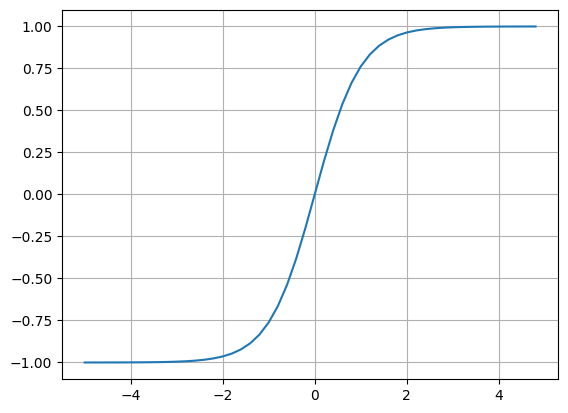

In [3]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

Chain rule

Derivatives rule

In [4]:
class Value:
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"


  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out


  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out


  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supports int/float powers"
    out = Value(self.data**other, (self, ), f'**{other}')

    def _backward():
      self.grad += other * self.data ** (other - 1) * out.grad
    out._backward = _backward

    return out


  def __neg__(self):     # -self
    return self * -1


  def __sub__(self, other):     # self - other
    return self + (-other)


  def __rmul__(self, other):     # other * self
    return self * other


  def __truediv__(self, other):     # self / other
    return self * other**-1


  def tanh(self):
    x = self.data
    t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward

    return out


  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
        self.grad += out.data * out.grad
    out._backward = _backward

    return out


  def backward(self):
    topo = []
    visited = set()

    def build_topo(v):
      if v not in visited:
        visited.add(v)

        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self )

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()


In [5]:
a = Value(2.0)
b = Value(4.0)
a-b

Value(data=-2.0)

In [6]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()

  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})   # LR left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))

    # for any value in the graph, create a rectangular node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

Back Propagation

In [7]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights of the neuron w1, w2 (i.e synaptic strength of each input)
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# output
o = n.tanh(); o.label = 'o'


# backward pass
o.backward()

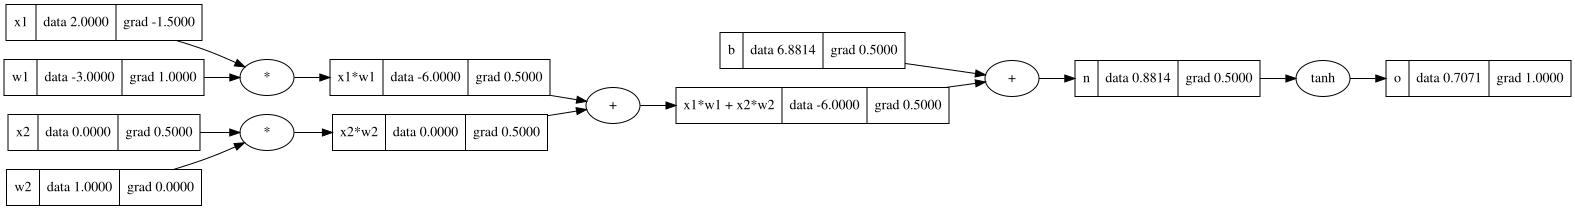

In [8]:
draw_dot(o)

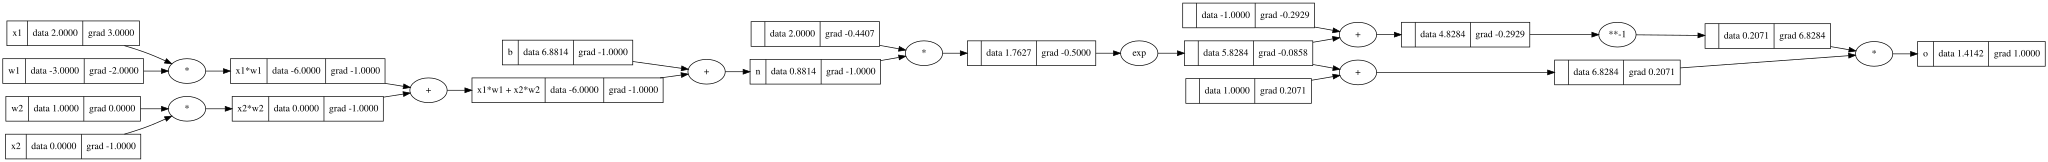

In [9]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights of the neuron w1, w2 (i.e synaptic strength of each input)
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# ----------------------------
# output
e = (2*n).exp()
o = (e + 1) / (e - 1)
# ----------------------------
o.label = 'o'

# backward pass
o.backward()

draw_dot(o)

In [10]:
# with _backward()

o.grad = 1.0
o._backward()
n._backward()
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()

In [11]:
# manual backward pass

x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

# How does back propagation flow through "+"?
# It becomes 1 * the gradient of the precident; i.e they each get the same value
x1w1.grad = 0.5
x2w2.grad = 0.5

x1w1x2w2.grad = 0.5

# b.grad = 0.5

# o = tanh(n)
# do/dn = 1 - tanh(x)**2 = 1 - o**2
# So, n.grad = 1 - (o.data)**2
n.grad = 0.5

o.grad = 1.0

# **What are Neural Nets?**

Neural nets are fairly simple mathematical expressions, like multi-layer perceptron, that take input as the data (the weights and parameters of the neural net), mathematical expression for the forward pass, follwed by a loss function.

The loss function measures the accuracy of the predictions. Usually, the loss would be low when the predictions are matching the target (i.e. the network is behaving normally). The loss function is (or can be) manipulated, so that the when the loss is low, the network is doing what it is expected to do.

Back propagation, backward pass, on the loss to get gradients informs us on how to tune all the parameters to decrease the loss locally. The reiteration over and over (i.e. tuning the parameters to achieve minimum loss) of this process is termed "Gradient descent".



In [12]:
import torch

In [15]:

x1 = torch.Tensor([2.0]).double()                 ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                 ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()                ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                 ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()   ; b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [16]:
import random

class Neuron:
  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]


class Layer:
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    # return [p for neuron in self.neurons for p in neuron.parameters()]
    params = []
    for neuron in self.neurons:
      ps = neuron.parameters()
      params.extend(ps)
    return params


# multi layer perceptron
class MLP:
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


In [17]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.6956822753242724)

In [18]:
print(len(n.parameters()))
print("-----")
n.parameters()

41
-----


[Value(data=0.3127791815833285),
 Value(data=-0.3354639456386772),
 Value(data=0.644434411364462),
 Value(data=0.4978505548899974),
 Value(data=-0.8306370780712222),
 Value(data=-0.45584641662148884),
 Value(data=0.5090595112218519),
 Value(data=-0.9734090159913589),
 Value(data=0.20882426870643922),
 Value(data=-0.2130264317877939),
 Value(data=-0.03827772782247463),
 Value(data=0.7823010184707546),
 Value(data=0.7227484086440179),
 Value(data=0.5901156831959788),
 Value(data=0.9912037225902679),
 Value(data=-0.7044782841283905),
 Value(data=-0.3011278577737464),
 Value(data=-0.7478501333771561),
 Value(data=-0.014137644301297936),
 Value(data=0.019612645656685412),
 Value(data=0.9125020924551317),
 Value(data=0.37674165145533456),
 Value(data=-0.28451171129491337),
 Value(data=-0.7260228151449069),
 Value(data=-0.9058462732522161),
 Value(data=-0.7434463962804307),
 Value(data=-0.4887475089215412),
 Value(data=-0.5056209372572584),
 Value(data=0.19554739919214015),
 Value(data=0.8627

In [296]:
# draw_dot(n(x))

In [19]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]     # desired targets

In [96]:
for k in range(20):

  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))

  # backward pass
  for p in n.parameters():
    p.grad = 0.0
  loss.backward()

  # update i.e. stochastic gradient descent
  for p in n.parameters():
    p.data += -0.5  *  p.grad

  print(k, loss.data)

0 7.68422665474325e-05
1 7.675137840901126e-05
2 7.666070366030418e-05
3 7.657024155254868e-05
4 7.647999134048314e-05
5 7.638995228230838e-05
6 7.630012363969536e-05
7 7.621050467773233e-05
8 7.612109466492812e-05
9 7.603189287319026e-05
10 7.594289857778992e-05
11 7.585411105736318e-05
12 7.576552959387836e-05
13 7.567715347261541e-05
14 7.558898198215758e-05
15 7.550101441436298e-05
16 7.541325006434804e-05
17 7.532568823047157e-05
18 7.523832821431833e-05
19 7.515116932066716e-05


In [97]:
ypred

[Value(data=0.995993445700093),
 Value(data=-0.9963475744797075),
 Value(data=-0.9950802163662043),
 Value(data=0.9953573489493701)]

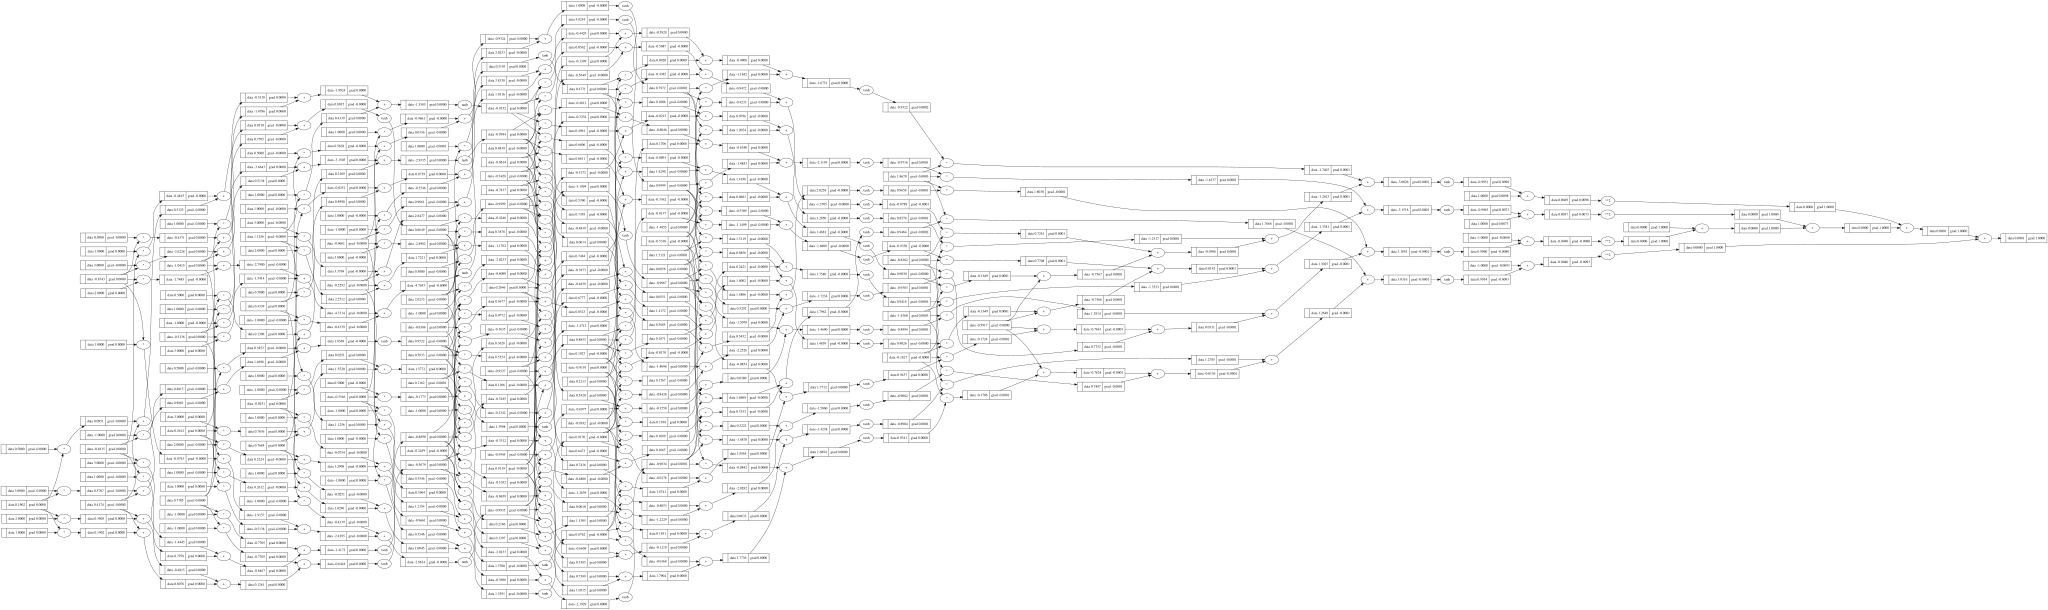

In [98]:
draw_dot(loss)